# 01. Data understanding and preprocessing
Download the competition data, inspect its structure, run EDA and build the subsampled training set used by all detectors.

In [28]:
import os, glob, json, zipfile, subprocess, sys, shutil, platform
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()), Path.cwd())
DATA_DIR = PROJECT / "data"
ZIP_DIR, RAW_DIR = DATA_DIR / "zip", DATA_DIR / "raw"
ZIP_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)
ROOT = RAW_DIR
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
print("cwd:    ", Path.cwd())
print("project:", PROJECT)

cwd:     /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai
project: /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai


In [ ]:
%pip install -q -U kaggle
if not list(ZIP_DIR.glob("*.zip")):
    subprocess.run(["kaggle", "competitions", "download", "-c", COMP, "-p", str(ZIP_DIR)], check=True)
print([(p.name, f"{p.stat().st_size / 1e9:.2f} GB") for p in ZIP_DIR.glob("*.zip")])

Note: you may need to restart the kernel to use updated packages.


100%|██████████| 9.88G/9.88G [10:01<00:00, 17.6MB/s]  



[('multiple-object-video-detection-hw-2-ucu-ai-2026.zip', '10.61 GB')]


In [16]:
# Download + extract only if the raw data is incomplete; broken archives are removed and re-downloaded
REQUIRED = ["test_images.csv", "train/annotations_coco.json", "val/annotations_coco.json", "train/data.yaml"]
missing = lambda: [f for f in REQUIRED if not (RAW_DIR / f).exists()]

if not missing():
    print("raw data already in place, nothing to download")
else:
    print("missing:", missing())
    for z in ZIP_DIR.glob("*.zip"):
        if not zipfile.is_zipfile(z):
            print("removing broken archive:", z.name); z.unlink()
    if not list(ZIP_DIR.glob("*.zip")):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)
        kaggle_bin = shutil.which("kaggle") or str(Path(sys.executable).parent / "kaggle")
        subprocess.run([kaggle_bin, "competitions", "download", "-c", COMP, "-p", str(ZIP_DIR)], check=True)
    for z in ZIP_DIR.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(RAW_DIR)
    assert not missing(), f"still missing after extraction: {missing()}"

for z in ZIP_DIR.glob("*.zip"):          # the archive is not needed after extraction (~10 GB)
    z.unlink()
print("free disk:", round(shutil.disk_usage(PROJECT).free / 1e9, 1), "GB")

raw data already in place, nothing to download
free disk: 16.9 GB


In [17]:
for split in ["train", "val"]:
    n_clips = len(os.listdir(ROOT / split / "images"))
    n_img = len(glob.glob(str(ROOT / split / "images" / "*" / "*.jpg")))
    n_ign = len(glob.glob(str(ROOT / split / "ignore" / "*" / "*.txt")))
    print(f"{split}: {n_clips} clips, {n_img} frames, {n_ign} frames with ignore regions")
print("test:", len(glob.glob(str(ROOT / "test" / "images" / "*" / "*.jpg"))), "frames")
print("\ndata.yaml:\n" + (ROOT / "train" / "data.yaml").read_text())

train: 56 clips, 24201 frames, 18090 frames with ignore regions
val: 7 clips, 2846 frames, 1434 frames with ignore regions
test: 3811 frames

data.yaml:
path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



In [18]:
coco_tr = json.load(open(ROOT / "train" / "annotations_coco.json"))
print("keys:", list(coco_tr.keys()))
print("categories:", coco_tr["categories"])
print("image example:", coco_tr["images"][0])
print("annotation example:", coco_tr["annotations"][0])
print("n images:", len(coco_tr["images"]), "| n annotations:", len(coco_tr["annotations"]),
      "| crowd/ignore:", sum(a["iscrowd"] for a in coco_tr["annotations"]))
del coco_tr   # free memory, EDA reloads it in a table form

test_df = pd.read_csv(ROOT / "test_images.csv")
display(test_df.head(3))
print("test frames per clip:", test_df.groupby("clip").size().describe().round(1).to_dict())
print("test image sizes:\n", test_df.groupby(["width", "height"]).size())

keys: ['info', 'categories', 'videos', 'images', 'annotations']
categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]
image example: {'id': 1, 'file_name': 'images/uav0000013_00000_v/0000001.jpg', 'width': 1344, 'height': 756, 'video_id': 1, 'video': 'uav0000013_00000_v', 'frame_id': 1}
annotation example: {'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [424, 543, 35, 88], 'area': 3080, 'iscrowd': 0, 'truncation': 0, 'occlusion': 0, 'track_id': 2, 'orig_category_id': 1}
n images: 24201 | n annotations: 1616260 | crowd/ignore: 510744


,image_id,file_name,clip,frame,width,height
0,clip_001_0000001,test/images/clip_001/0000001.jpg,clip_001,1,1920,1080
1,clip_001_0000002,test/images/clip_001/0000002.jpg,clip_001,2,1920,1080
2,clip_001_0000003,test/images/clip_001/0000003.jpg,clip_001,3,1920,1080


test frames per clip: {'count': 48.0, 'mean': 79.4, 'std': 34.5, 'min': 35.0, '25%': 48.8, '50%': 73.5, '75%': 108.2, 'max': 148.0}
test image sizes:
 width  height
680    382        321
960    540        279
1344   756        441
1360   764       1474
1904   1072       305
1920   1080       991
dtype: int64


In [19]:
print("Python", sys.version.split()[0], "|", platform.platform())
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU",
      "|", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB VRAM" if torch.cuda.is_available() else "")

Python 3.12.3 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch 2.14.1+cu130 | CUDA: True | NVIDIA GeForce RTX 5070 Laptop GPU | 8.1 GB VRAM


## 1. Exploratory data analysis
We use the COCO annotation files: they contain track ids, occlusion and video/frame ids, which the YOLO txt files do not.

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
sns.set_theme(style="whitegrid")

def load_split(split):
    # returns image table, target objects (iscrowd=0) and ignored regions (iscrowd=1)
    coco = json.load(open(ROOT / split / "annotations_coco.json"))
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    ann = pd.DataFrame(coco["annotations"])
    ann[["x", "y", "w", "h"]] = pd.DataFrame(ann.pop("bbox").tolist(), index=ann.index)
    ann = ann.merge(imgs[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    objs = ann[ann.iscrowd == 0].copy()
    objs["cls"] = objs.category_id - 1
    objs["cls_name"] = objs.cls.map(dict(enumerate(CLASSES)))
    objs["sqrt_area"] = np.sqrt(objs.w * objs.h)
    imgs["split"] = split
    return imgs, objs, ann[ann.iscrowd == 1].copy()

imgs_tr, obj_tr, ign_tr = load_split("train")
imgs_va, obj_va, ign_va = load_split("val")
imgs_all = pd.concat([imgs_tr, imgs_va], ignore_index=True)
obj_all = pd.concat([obj_tr.assign(split="train"), obj_va.assign(split="val")], ignore_index=True)
ign_all = pd.concat([ign_tr, ign_va], ignore_index=True)

print(f"train: {len(imgs_tr)} frames, {len(obj_tr)} objects, {len(ign_tr)} ignore boxes")
print(f"val:   {len(imgs_va)} frames, {len(obj_va)} objects, {len(ign_va)} ignore boxes")
print("ignore boxes by orig_category_id:", ign_all.orig_category_id.value_counts().to_dict())

train: 24201 frames, 1105516 objects, 510744 ignore boxes
val:   2846 frames, 114132 objects, 31960 ignore boxes
ignore boxes by orig_category_id: {0: 530904, 11: 11800}


### 1.1 Class distribution

,train,val,train %,val %
cls_name,,,,
person,328701,50312,29.7,44.1
bicycle,40255,6022,3.6,5.3
car,505301,31821,45.7,27.9
van,46940,6842,4.2,6.0
truck,30498,1359,2.8,1.2
tricycle,41349,5487,3.7,4.8
bus,9653,264,0.9,0.2
motor,102819,12025,9.3,10.5


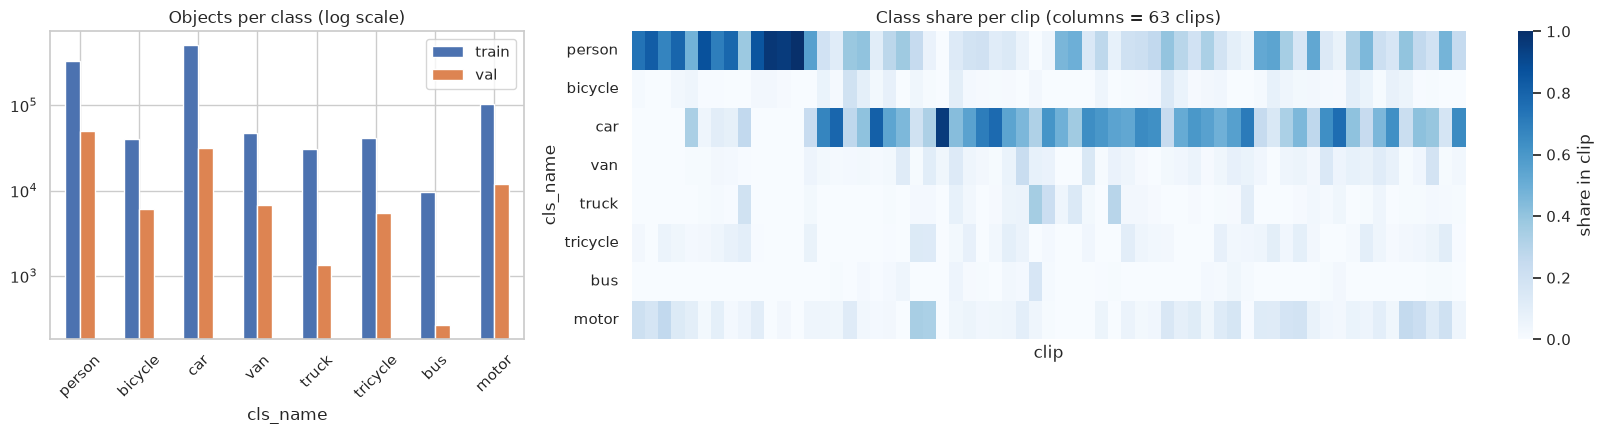

In [21]:
cls_counts = pd.DataFrame({"train": obj_tr.cls_name.value_counts(),
                           "val": obj_va.cls_name.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
for s in ["train", "val"]:
    cls_counts[f"{s} %"] = (cls_counts[s] / cls_counts[s].sum() * 100).round(1)
display(cls_counts)

share = pd.crosstab(obj_all.video, obj_all.cls_name, normalize="index").reindex(columns=CLASSES).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})
cls_counts[["train", "val"]].plot.bar(ax=axes[0], logy=True, rot=45)
axes[0].set_title("Objects per class (log scale)")
sns.heatmap(share.T, ax=axes[1], cmap="Blues", xticklabels=False, cbar_kws={"label": "share in clip"})
axes[1].set_title("Class share per clip (columns = 63 clips)"); axes[1].set_xlabel("clip")
plt.tight_layout(); plt.show()

### 1.2 Object sizes and the choice of input resolution
COCO size buckets: small < 32², medium 32²–96², large > 96² px (in original image pixels).

coco_size,small,medium,large
split,,,
train,0.249,0.635,0.116
val,0.192,0.695,0.113


,count,10%,50%,90%
cls_name,,,,
person,379013.0,20.5,36.7,63.0
bicycle,46277.0,25.8,43.9,75.7
car,537122.0,28.4,57.5,121.7
van,53782.0,28.7,51.3,128.6
truck,31857.0,33.1,73.9,181.4
tricycle,46836.0,25.0,54.5,104.4
bus,9917.0,41.8,111.7,264.7
motor,114844.0,20.3,39.8,68.5


,long side S,"median sqrt(area), px",share < 8 px,share < 16 px
0,640,15.286,0.097,0.536
1,960,22.929,0.018,0.235
2,1280,30.572,0.006,0.097
3,1536,36.686,0.002,0.048


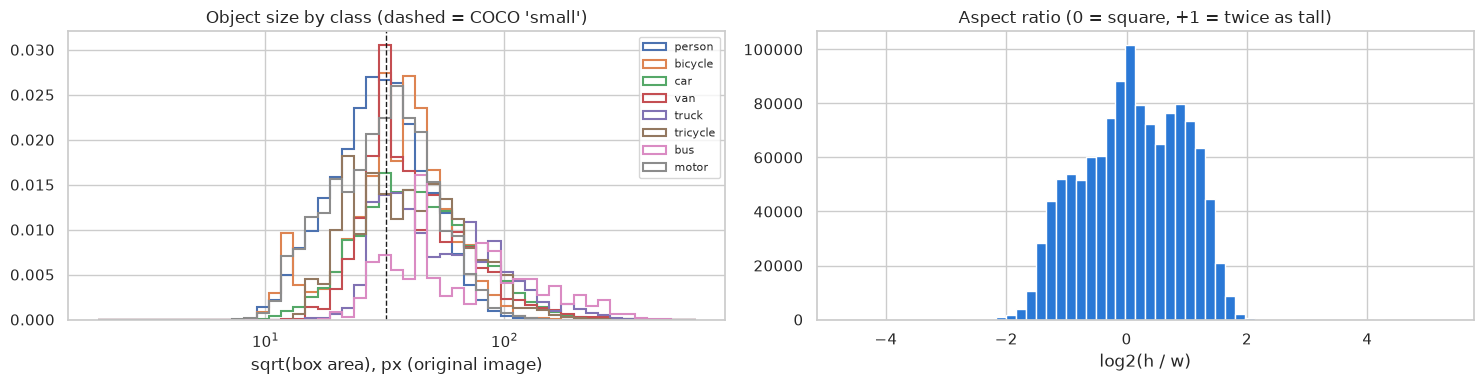

In [22]:
obj_all["coco_size"] = pd.cut(obj_all.w * obj_all.h, [0, 32**2, 96**2, np.inf],
                              labels=["small", "medium", "large"], right=False)
display(pd.crosstab(obj_all.split, obj_all.coco_size, normalize="index").round(3))
display(obj_all.groupby("cls_name").sqrt_area.describe(percentiles=[.1, .5, .9])
        .reindex(CLASSES)[["count", "10%", "50%", "90%"]].round(1))

# how small objects become after resizing the long image side to S pixels
long_side = obj_all[["width", "height"]].max(axis=1)
rows = []
for S in [640, 960, 1280, 1536]:
    s = obj_all.sqrt_area * S / long_side
    rows.append({"long side S": S, "median sqrt(area), px": s.median(),
                 "share < 8 px": (s < 8).mean(), "share < 16 px": (s < 16).mean()})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
bins = np.logspace(0.3, 2.8, 50)
for c in CLASSES:
    axes[0].hist(obj_all.loc[obj_all.cls_name == c, "sqrt_area"], bins=bins, histtype="step", lw=1.5, label=c, density=True)
axes[0].set_xscale("log"); axes[0].axvline(32, color="k", ls="--", lw=1)
axes[0].set_xlabel("sqrt(box area), px (original image)"); axes[0].set_title("Object size by class (dashed = COCO 'small')")
axes[0].legend(fontsize=8)
axes[1].hist(np.log2(obj_all.h / obj_all.w), bins=60, color="#2a78d6")
axes[1].set_xlabel("log2(h / w)"); axes[1].set_title("Aspect ratio (0 = square, +1 = twice as tall)")
plt.tight_layout(); plt.show()

In [23]:
# k-means on log(w, h) of train boxes rescaled to long side 1280 (the resolution we plan to train at)
from sklearn.cluster import KMeans
smp = obj_tr.sample(200_000, random_state=SEED)
scale = 1280 / smp[["width", "height"]].max(axis=1)
log_wh = np.log(np.c_[smp.w * scale, smp.h * scale])
km = KMeans(n_clusters=9, random_state=SEED, n_init=10).fit(log_wh)
centers = np.exp(km.cluster_centers_)
centers = centers[np.argsort(centers.prod(axis=1))]
display(pd.DataFrame({"w": centers[:, 0], "h": centers[:, 1],
                      "sqrt(area)": np.sqrt(centers.prod(axis=1)),
                      "h/w": centers[:, 1] / centers[:, 0]}).round(1))

,w,h,sqrt(area),h/w
0,9.4,16.3,12.4,1.7
1,19.9,16.2,17.9,0.8
2,16.0,30.7,22.2,1.9
3,32.0,23.6,27.5,0.7
4,27.8,45.6,35.6,1.6
5,53.8,31.1,40.9,0.6
6,51.6,67.1,58.8,1.3
7,95.9,48.1,67.9,0.5
8,128.0,100.6,113.5,0.8


### 1.3 Scene density and ignored regions per clip

objects per frame: {'count': 27047.0, 'mean': 45.1, 'std': 31.1, 'min': 0.0, '50%': 42.0, '90%': 90.0, '99%': 140.0, 'max': 180.0}
frames with > 100 objects: 7.5% | > 300: 0.00% | > 500: 0.00%

Train clips summary:


,frames,width,height,median objs/frame,"median size, px",ignored area %
count,56.0,56.0,56.0,56.0,56.0,56.0
mean,432.2,1967.7,1106.8,49.2,50.7,20.4
std,275.1,459.5,258.5,33.1,14.6,26.5
min,58.0,1344.0,756.0,5.0,24.5,0.0
25%,223.5,1904.0,1071.0,25.8,41.5,3.7
50%,383.5,1904.0,1071.0,43.5,47.7,8.3
75%,550.0,1908.0,1073.2,57.5,56.4,26.6
max,1424.0,2720.0,1530.0,150.0,86.8,100.0


Val clips:


,split,frames,width,height,median objs/frame,"median size, px",top class,ignored area %
video,,,,,,,,
uav0000086_00000_v,val,464,1344,756,50.5,39.8,person,5.1
uav0000117_02622_v,val,349,2720,1530,41.0,65.1,person,64.4
uav0000137_00458_v,val,233,2688,1512,105.0,73.2,person,16.0
uav0000182_00000_v,val,363,1344,756,41.0,32.4,motor,7.9
uav0000268_05773_v,val,978,3840,2160,14.0,48.4,car,0.0
uav0000305_00000_v,val,184,1904,1071,35.5,77.0,car,0.0
uav0000339_00001_v,val,275,1904,1071,47.0,48.5,person,19.5


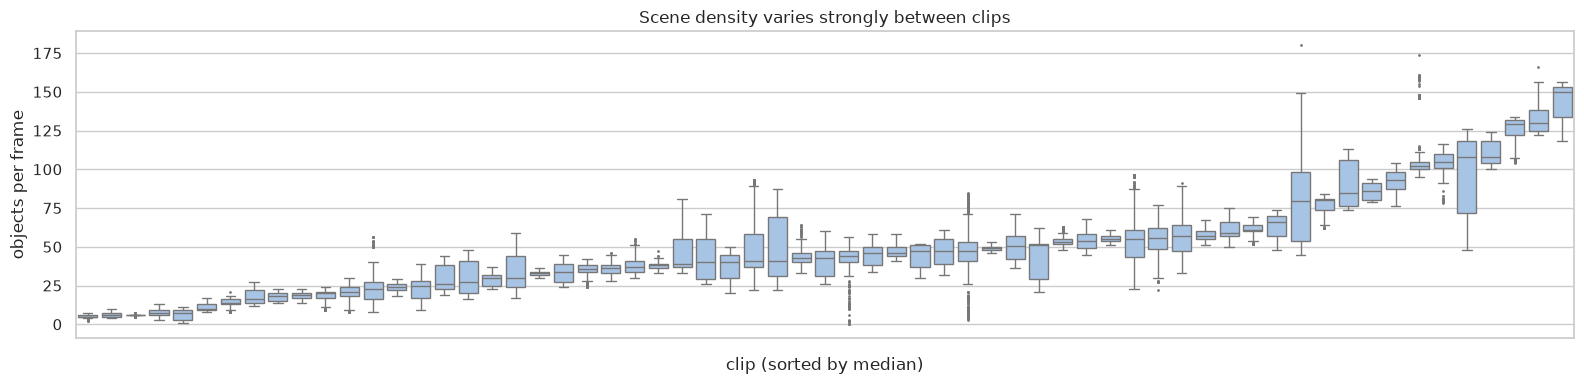

In [24]:
per_frame = (obj_all.groupby(["video", "frame_id"]).size().rename("n")
             .reindex(pd.MultiIndex.from_frame(imgs_all[["video", "frame_id"]]), fill_value=0).reset_index())
print("objects per frame:", per_frame.n.describe(percentiles=[.5, .9, .99]).round(1).to_dict())
print(f"frames with > 100 objects: {(per_frame.n > 100).mean():.1%} | > 300: {(per_frame.n > 300).mean():.2%} | > 500: {(per_frame.n > 500).mean():.2%}")

# share of the frame covered by ignored regions (sum of box areas, capped at 1)
ign_all["frac"] = ign_all.w * ign_all.h / (ign_all.width * ign_all.height)
ign_frame = ign_all.groupby(["video", "frame_id"]).frac.sum().clip(upper=1)

clip_tab = imgs_all.groupby("video").agg(split=("split", "first"), frames=("image_id", "size"),
                                         width=("width", "first"), height=("height", "first"))
clip_tab["median objs/frame"] = per_frame.groupby("video").n.median()
clip_tab["median size, px"] = obj_all.groupby("video").sqrt_area.median().round(1)
clip_tab["top class"] = obj_all.groupby("video").cls_name.agg(lambda s: s.value_counts().index[0])
clip_tab["ignored area %"] = (ign_frame.groupby("video").sum() / clip_tab.frames * 100).reindex(clip_tab.index).fillna(0).round(1)

print("\nTrain clips summary:"); display(clip_tab[clip_tab.split == "train"].describe().round(1))
print("Val clips:"); display(clip_tab[clip_tab.split == "val"])

order = per_frame.groupby("video").n.median().sort_values().index
fig, ax = plt.subplots(figsize=(16, 4))
sns.boxplot(data=per_frame, x="video", y="n", order=order, ax=ax, fliersize=1, color="#9ec3ef")
ax.set_xticklabels([]); ax.set_xlabel("clip (sorted by median)"); ax.set_ylabel("objects per frame")
ax.set_title("Scene density varies strongly between clips")
plt.tight_layout(); plt.show()

### 1.4 Temporal redundancy: how similar are neighbouring frames?
We follow each object (track_id) k frames ahead. If the same object barely moves after k frames,
neighbouring frames carry almost the same information and we can subsample with step k.

In [25]:
tr = obj_tr[["video", "track_id", "frame_id", "x", "y", "w", "h"]]
rows = []
for k in [1, 5, 10, 20, 30]:
    m = tr.merge(tr.assign(frame_id=tr.frame_id - k), on=["video", "track_id", "frame_id"], suffixes=("", "_k"))
    ix = (np.minimum(m.x + m.w, m.x_k + m.w_k) - np.maximum(m.x, m.x_k)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y_k + m.h_k) - np.maximum(m.y, m.y_k)).clip(lower=0)
    iou = ix * iy / (m.w * m.h + m.w_k * m.h_k - ix * iy)
    shift = np.hypot(m.x + m.w / 2 - m.x_k - m.w_k / 2, m.y + m.h / 2 - m.y_k - m.h_k / 2) / np.sqrt(m.w * m.h)
    rows.append({"step k": k, "objects still present": len(m) / len(tr),
                 "median IoU with itself": iou.median(), "median shift / box size": shift.median()})
display(pd.DataFrame(rows).round(3))

,step k,objects still present,median IoU with itself,median shift / box size
0,1,0.993,0.897,0.044
1,5,0.966,0.597,0.209
2,10,0.933,0.357,0.416
3,20,0.870,0.102,0.807
4,30,0.811,0.000,1.159


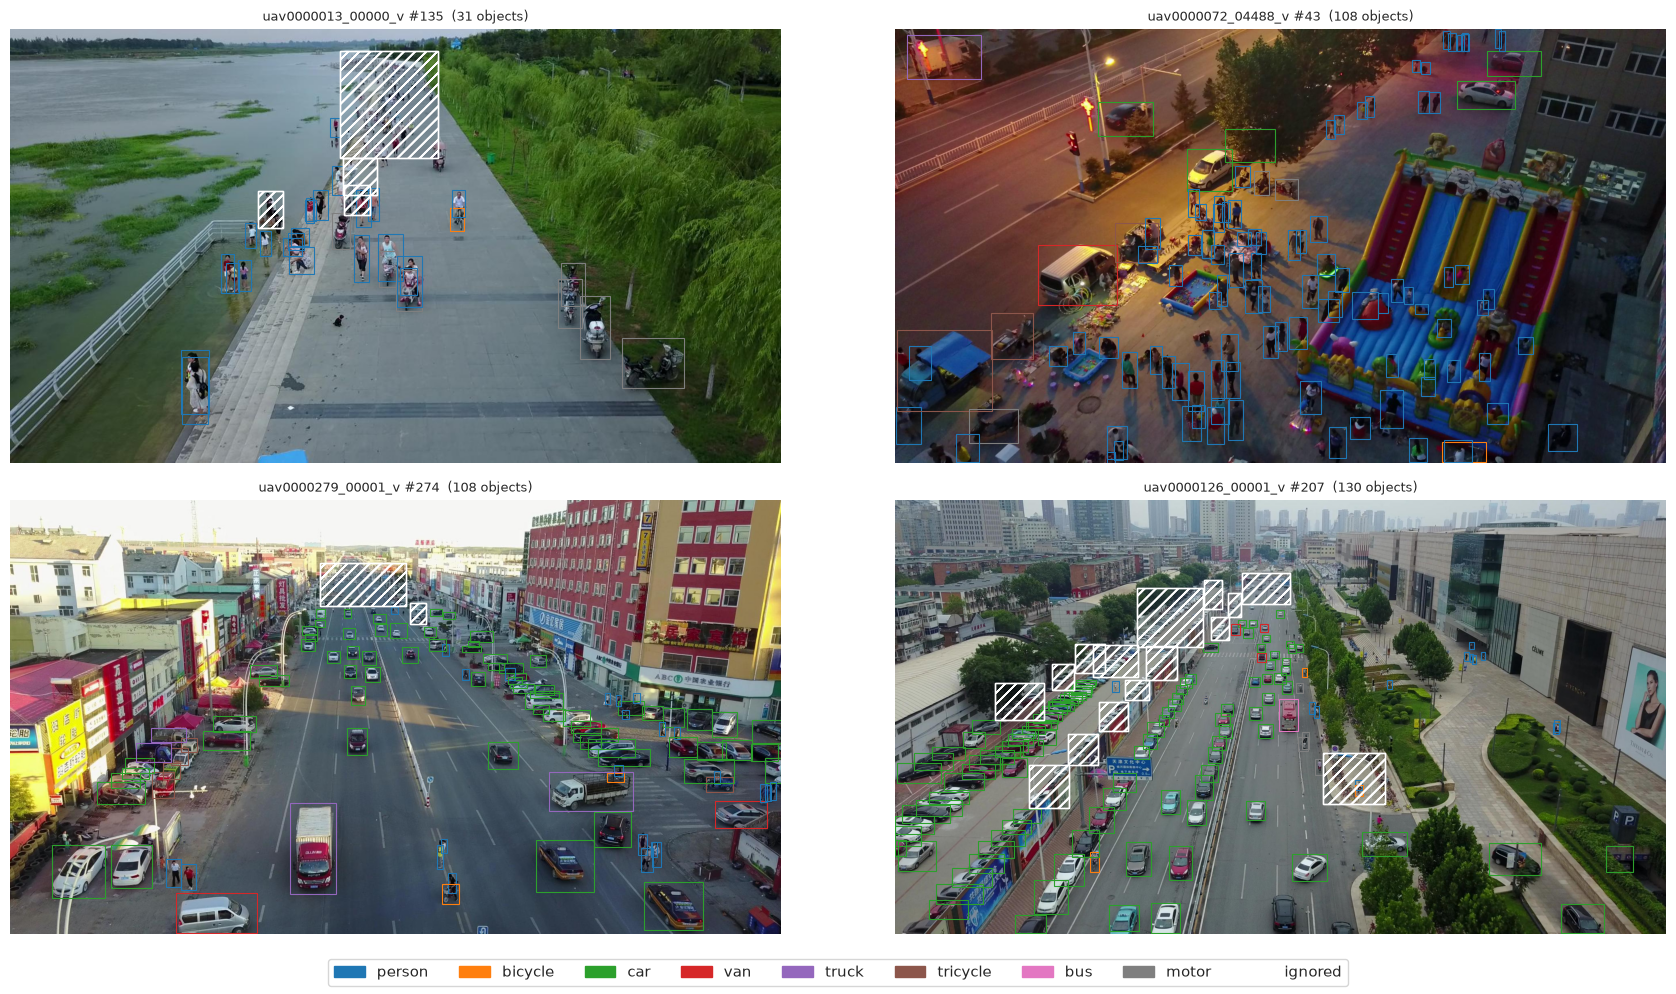

In [26]:
# draw GT boxes (coloured by class) and ignored regions (hatched) on frames from different clips
import matplotlib.patches as mpatches
from PIL import Image
PALETTE = plt.get_cmap("tab10").colors

def show_gt(ax, split, row, objs, igns):
    ax.imshow(Image.open(ROOT / split / row.file_name)); ax.axis("off")
    for o in objs.itertuples():
        ax.add_patch(mpatches.Rectangle((o.x, o.y), o.w, o.h, fill=False, ec=PALETTE[o.cls], lw=0.8))
    for g in igns.itertuples():
        ax.add_patch(mpatches.Rectangle((g.x, g.y), g.w, g.h, fill=False, ec="white", hatch="///", lw=0.8))
    ax.set_title(f"{row.video} #{row.frame_id}  ({len(objs)} objects)", fontsize=9)

rng = np.random.RandomState(SEED)
picked = rng.choice(clip_tab[clip_tab.split == "train"].index, 4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, vid in zip(axes.ravel(), picked):
    row = imgs_tr[imgs_tr.video == vid].iloc[len(imgs_tr[imgs_tr.video == vid]) // 2]
    show_gt(ax, "train", row, obj_tr[obj_tr.image_id == row.image_id], ign_tr[ign_tr.image_id == row.image_id])
handles = [mpatches.Patch(color=PALETTE[i], label=c) for i, c in enumerate(CLASSES)] + \
          [mpatches.Patch(fill=False, hatch="///", label="ignored")]
fig.legend(handles=handles, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

In [30]:
# Shared code lives in common.py (repo root); autoreload picks up edits without restarting the kernel
%load_ext autoreload
%autoreload 2
%pip install -q pycocotools opencv-python
import cv2
sys.path.insert(0, str(PROJECT))
from common import (load_split, select_frames, build_yolo_dataset, make_coco_gt, coco_evaluate,
                    gt_as_predictions, draw_boxes, PROC, CLASSES, SEED)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Note: you may need to restart the kernel to use updated packages.


## 2. Preprocessing
Decisions (based on section 1):
* **Split by sequence.** The organisers' `val/` (7 clips) is our hold-out set; no clip appears in both train and val.
* **Frame subsampling.** Train: every 10th frame of each clip (neighbouring frames are near duplicates, see 1.4).
  Val: 60 evenly spaced frames per clip, so that the long 4K clip does not dominate the metric.
* **Ignored regions.** In training images they are painted grey (114) and objects that are ≥ 50 % inside them are removed,
  so the model is not taught that these areas are background. Validation images are not changed: ignored regions
  enter the evaluation as `iscrowd=1` boxes (detections there are not counted as false positives), like on Kaggle.
* **Resolution.** Training images are stored with the long side ≤ 1920 px (as in the test set); each detector
  resizes them to its input size (1280 for model comparison). Labels stay normalised, so resizing does not change them.

In [31]:
TRAIN_STEP = 10       # section 1.4: at k = 10 objects moved ~0.4 of their size, frames are no longer near duplicates
VAL_PER_CLIP = 60     # balanced evaluation across the 7 validation clips

train_frames = select_frames(imgs_tr, step=TRAIN_STEP)
val_frames = select_frames(imgs_va, per_clip=VAL_PER_CLIP)
print(f"train: {len(train_frames)} frames from {train_frames.video.nunique()} clips "
      f"({obj_tr.image_id.isin(train_frames.image_id).sum()} objects)")
print(f"val:   {len(val_frames)} frames from {val_frames.video.nunique()} clips "
      f"({obj_va.image_id.isin(val_frames.image_id).sum()} objects)")
assert not set(train_frames.video) & set(val_frames.video), "a clip is in both train and val"

train: 2446 frames from 56 clips (112264 objects)
val:   420 frames from 7 clips (20624 objects)


In [32]:
# YOLO-format dataset used by all detectors: data/proc/s10/{images,labels}/{train,val}
stats = build_yolo_dataset("s10", {
    "train": ("train", train_frames, obj_tr, ign_tr, True),    # ignored regions masked
    "val":   ("val",   val_frames,   obj_va, ign_va, False)})  # unchanged, only for Ultralytics monitoring
display(stats.groupby("part")[["kept", "dropped"]].sum())
print("frames with > 50% of the area ignored:", stats[stats.ignored_frac > 0.5].groupby("part").size().to_dict())
print("disk used:", round(sum(f.stat().st_size for f in (PROC / "s10").rglob("*") if f.is_file()) / 1e9, 2), "GB")

,kept,dropped
part,,
train,110854,1410
val,20624,0


frames with > 50% of the area ignored: {}
disk used: 1.47 GB


In [33]:
# COCO ground truth for our validation frames; ignored regions are iscrowd=1 boxes for every class
VAL_GT = make_coco_gt(val_frames, obj_va, ign_va, "val", PROC / "val_gt.json")

# sanity check: GT boxes given as predictions must score mAP = 1.0
print({k: round(v, 3) for k, v in coco_evaluate(VAL_GT, gt_as_predictions(VAL_GT)).items()})

{'mAP': 1.0, 'AP50': 1.0, 'AP75': 1.0, 'AP_small': 1.0, 'AP_medium': 1.0, 'AP_large': 1.0, 'AP_person': 1.0, 'AP_bicycle': 1.0, 'AP_car': 1.0, 'AP_van': 1.0, 'AP_truck': 1.0, 'AP_tricycle': 1.0, 'AP_bus': 1.0, 'AP_motor': 1.0}


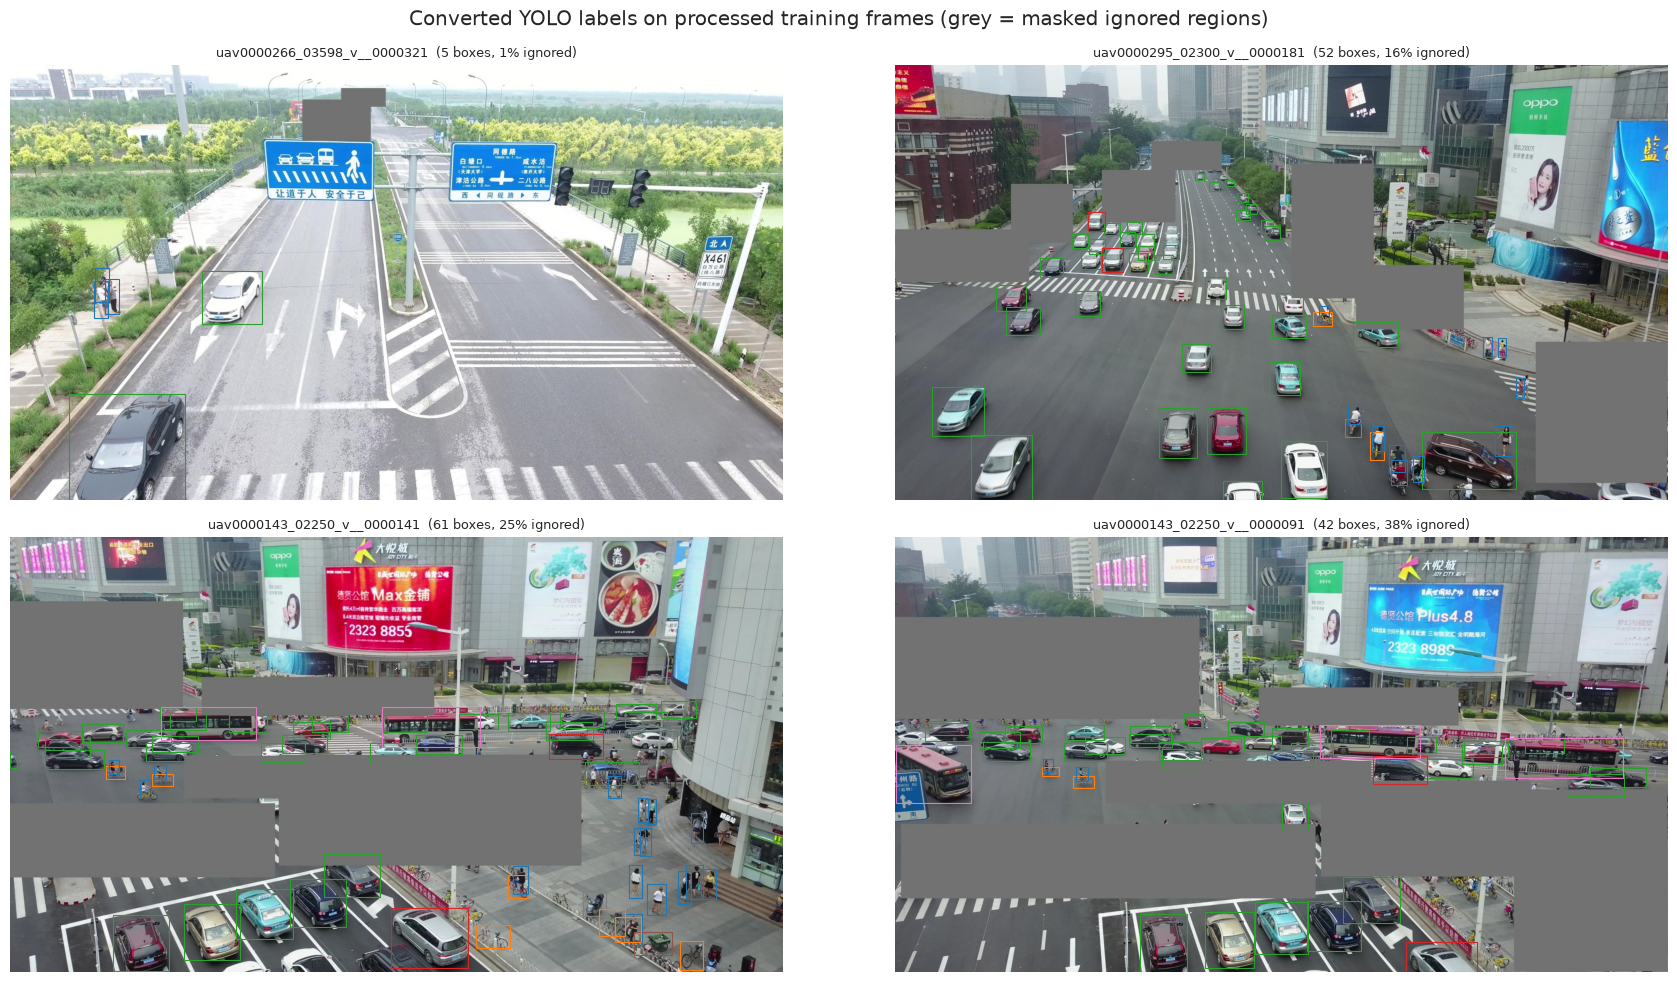

In [34]:
# Read back the written YOLO labels and draw them on the processed (masked) images
def read_yolo(stem, part="train", ds="s10"):
    img = cv2.imread(str(PROC / ds / "images" / part / f"{stem}.jpg"))[..., ::-1]
    h, w = img.shape[:2]
    lab = np.loadtxt(PROC / ds / "labels" / part / f"{stem}.txt", ndmin=2).reshape(-1, 5)
    cx, cy, bw, bh = lab[:, 1] * w, lab[:, 2] * h, lab[:, 3] * w, lab[:, 4] * h
    return img, np.c_[cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], lab[:, 0]

tr_stats = stats[stats.part == "train"]
picked = [tr_stats.sort_values("ignored_frac").key.iloc[i] for i in (len(tr_stats) // 2, -40, -15, -1)]
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, stem in zip(axes.ravel(), picked):
    img, boxes, cls = read_yolo(stem)
    ax.imshow(img); ax.axis("off"); draw_boxes(ax, boxes, cls)
    ax.set_title(f"{stem}  ({len(boxes)} boxes, {tr_stats.set_index('key').ignored_frac[stem]:.0%} ignored)", fontsize=9)
plt.suptitle("Converted YOLO labels on processed training frames (grey = masked ignored regions)")
plt.tight_layout(); plt.show()